# 01 - Exploring SF 311 cases

Goal: understand the data before building the two models in the README (photo -> category routing, and time-to-close).

Loads every monthly file `data/raw/sf311_YYYY-MM.parquet` (skipping `*_sample` files). If no full month exists yet, it falls back to the sample.
Photos are **never** downloaded or displayed here; we only look at the link host.

Sections: 1. Basic checks · 2. Volume per month · 3. Status · 4. Categories and label set · 5. Agencies · 6. Source channel · 7. Photo availability · 8. Resolution time · 9. Open cases (censoring) · 10. Map · 11. Summary

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_colwidth", 60)
pd.set_option("display.width", 140)
plt.rcParams.update({
    "figure.figsize": (10, 4.5),
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titleweight": "bold",
})

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"

full_files = sorted(p for p in RAW.glob("sf311_*.parquet") if "_sample" not in p.stem)
files = full_files or sorted(RAW.glob("sf311_*_sample.parquet"))
USING_SAMPLE = not full_files
print("Using sample only:" if USING_SAMPLE else f"{len(files)} full-month files:")
for p in files:
    print("  ", p.name)

df = pd.concat([pd.read_parquet(p).assign(file=p.stem) for p in files], ignore_index=True)
print(f"\n{len(df):,} rows, {df.shape[1]} columns")

12 full-month files:
   sf311_2025-11.parquet
   sf311_2025-12.parquet
   sf311_2026-01.parquet
   sf311_2026-02.parquet
   sf311_2026-03.parquet
   sf311_2026-04.parquet
   sf311_2026-05.parquet
   sf311_2026-06.parquet
   sf311_2026-07.parquet
   sf311_2026-08.parquet
   sf311_2026-09.parquet
   sf311_2026-10.parquet



867,349 rows, 18 columns


## 1. Basic checks

Column types, missing values and duplicate IDs. Months are taken from `requested_datetime` (the fetch filter), not from the file name.

In [2]:
df["month"] = df["requested_datetime"].dt.to_period("M")
dup = df["service_request_id"].duplicated().sum()
print(f"Duplicate service_request_id: {dup:,}")
print(f"Date range: {df['requested_datetime'].min()} -> {df['requested_datetime'].max()}")
missing = (df.isna().mean() * 100).round(1).rename("% missing").to_frame()
missing["dtype"] = df.dtypes.astype(str)
missing

Duplicate service_request_id: 0
Date range: 2025-11-01 00:00:25 -> 2026-10-31 23:59:45


,% missing,dtype
service_request_id,0.0,str
requested_datetime,0.0,datetime64[us]
closed_date,5.2,datetime64[us]
updated_datetime,0.0,datetime64[us]
status_description,0.0,str
status_notes,5.7,str
agency_responsible,0.0,str
service_name,0.0,str
service_subtype,0.3,str
service_details,33.7,str


In [3]:
# Drop duplicate IDs (if a re-run overlapped) and test submissions.
n0 = len(df)
df = df.drop_duplicates("service_request_id")
test_rows = (df["source"] == "Test").sum()
df = df[df["source"] != "Test"].copy()
print(f"Removed {n0 - len(df):,} rows ({test_rows:,} with source == 'Test'). Remaining: {len(df):,}")

Removed 617 rows (617 with source == 'Test'). Remaining: 866,732


## 2. Row counts per month

month,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
rows,65256,65413,74385,62852,74034,69687,77601,73720,73468,76166,76381,77769


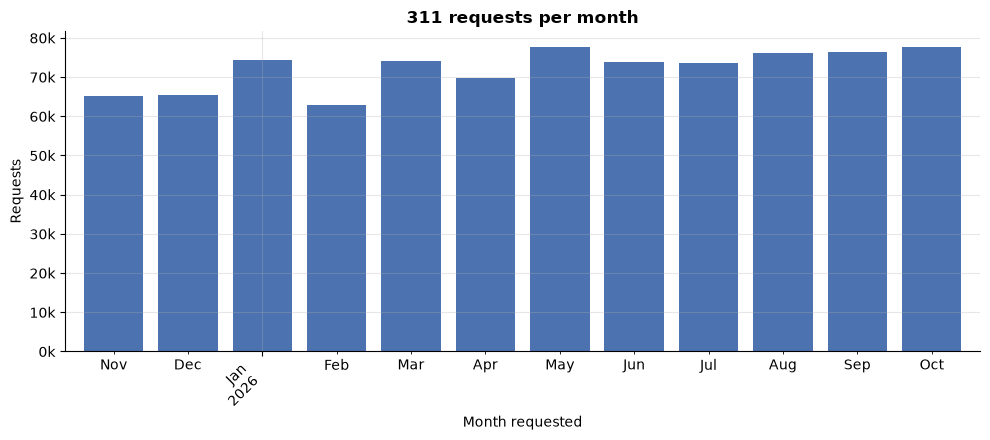

Mean 72,228 / month, min 62,852 (2026-02), max 77,769 (2026-10)


In [4]:
per_month = df.groupby("month").size().rename("rows")
display(per_month.to_frame().T)

fig, ax = plt.subplots()
per_month.plot.bar(ax=ax, color="#4C72B0", width=0.8)
ax.set_title("311 requests per month")
ax.set_xlabel("Month requested")
ax.set_ylabel("Requests")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1000:.0f}k"))
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
print(f"Mean {per_month.mean():,.0f} / month, min {per_month.min():,} ({per_month.idxmin()}), max {per_month.max():,} ({per_month.idxmax()})")

Volume is fairly stable month to month, so there is no need to reweight months for training. A time-based split (e.g. last 2 months as test) still gives a large test set.

## 3. Status / closed share

,% of cases
status_description,
Closed,94.8
Open,5.2


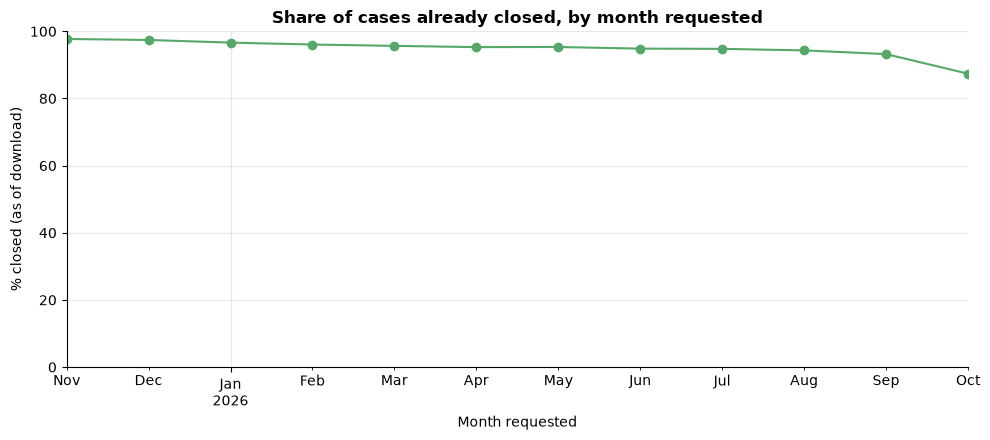

In [5]:
status = df["status_description"].value_counts(dropna=False)
display((status / len(df) * 100).round(1).rename("% of cases").to_frame())

closed_by_month = df["status_description"].eq("Closed").groupby(df["month"]).mean() * 100
fig, ax = plt.subplots()
closed_by_month.plot(ax=ax, marker="o", color="#55A868")
ax.set_title("Share of cases already closed, by month requested")
ax.set_xlabel("Month requested")
ax.set_ylabel("% closed (as of download)")
ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()

Most cases are closed, but the most recent months have a lower closed share simply because they have had less time to close. That is right-censoring (see section 9), not a change in city performance.

## 4. Categories: `service_name` and `service_subtype`

`service_name` is the broad category; `service_subtype` is finer. For a classifier we need to know how concentrated the volume is.

Distinct service_name: 42, distinct service_subtype: 264


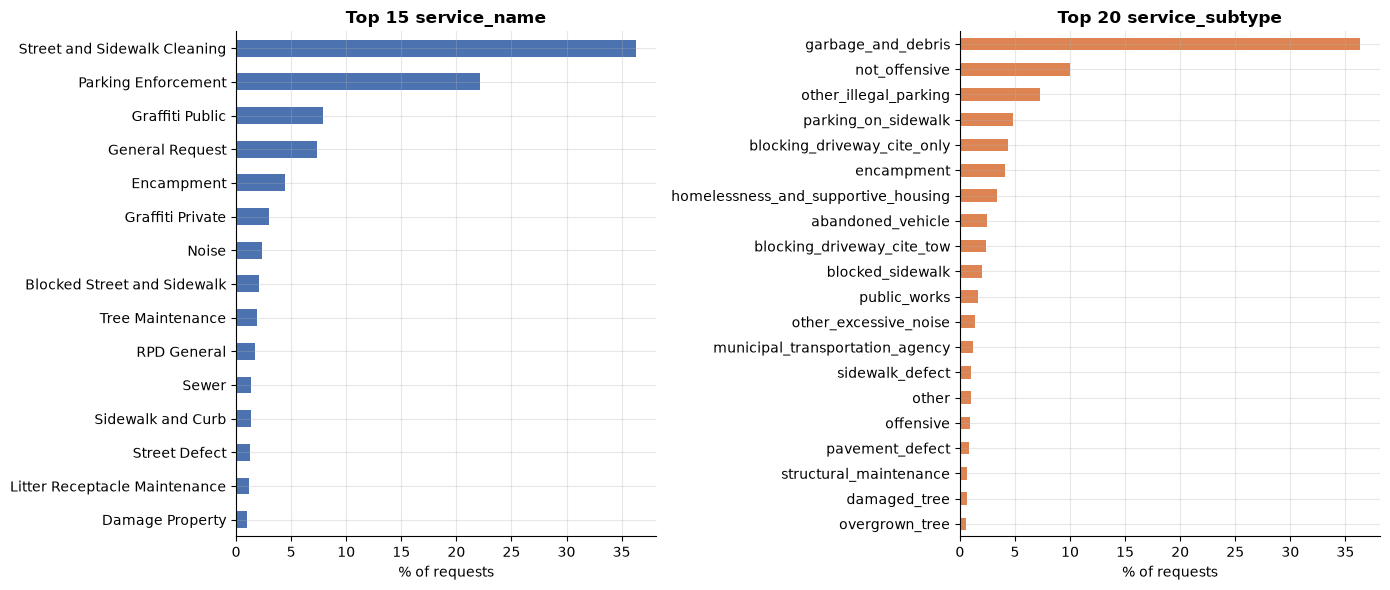

In [6]:
name_counts = df["service_name"].fillna("(missing)").value_counts()
sub_counts = df["service_subtype"].fillna("(missing)").value_counts()
print(f"Distinct service_name: {name_counts.size}, distinct service_subtype: {sub_counts.size}")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
(name_counts.head(15)[::-1] / len(df) * 100).plot.barh(ax=axes[0], color="#4C72B0")
axes[0].set_title("Top 15 service_name")
axes[0].set_xlabel("% of requests")
axes[0].set_ylabel("")
(sub_counts.head(20)[::-1] / len(df) * 100).plot.barh(ax=axes[1], color="#DD8452")
axes[1].set_title("Top 20 service_subtype")
axes[1].set_xlabel("% of requests")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

,service_name,service_subtype
distinct,42.0,264.0
n for 50%,2.0,3.0
n for 80%,6.0,12.0
n for 90%,11.0,27.0
n for 95%,15.0,47.0
n for 99%,20.0,102.0
classes with <100 cases,13.0,129.0
top-1 share %,36.3,36.3


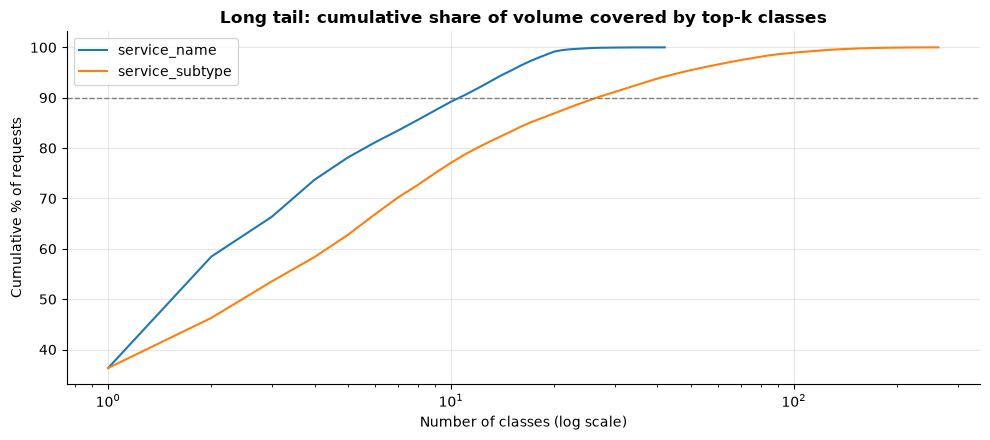

In [7]:
def coverage_stats(counts: pd.Series, label: str) -> pd.Series:
    cum = counts.cumsum() / counts.sum()
    return pd.Series({
        "distinct": counts.size,
        "n for 50%": int((cum < 0.50).sum() + 1),
        "n for 80%": int((cum < 0.80).sum() + 1),
        "n for 90%": int((cum < 0.90).sum() + 1),
        "n for 95%": int((cum < 0.95).sum() + 1),
        "n for 99%": int((cum < 0.99).sum() + 1),
        "classes with <100 cases": int((counts < 100).sum()),
        "top-1 share %": round(counts.iloc[0] / counts.sum() * 100, 1),
    }, name=label)

cov = pd.concat([coverage_stats(name_counts, "service_name"), coverage_stats(sub_counts, "service_subtype")], axis=1)
display(cov)

fig, ax = plt.subplots()
for counts, lab in [(name_counts, "service_name"), (sub_counts, "service_subtype")]:
    cum = counts.cumsum().to_numpy() / counts.sum() * 100
    ax.plot(np.arange(1, len(cum) + 1), cum, label=lab)
ax.axhline(90, ls="--", c="grey", lw=1)
ax.set_xscale("log")
ax.set_title("Long tail: cumulative share of volume covered by top-k classes")
ax.set_xlabel("Number of classes (log scale)")
ax.set_ylabel("Cumulative % of requests")
ax.legend()
plt.tight_layout()
plt.show()

### Proposed label set for photo classification

Two observations drive the proposal:
1. Only photo-bearing cases matter for the photo router, so the label set is built from cases **with a direct image link** (Cloudinary, see section 7).
2. Raw subtypes have a long tail; very small classes cannot be learned from photos and some are not visually distinct.

Proposal: use `service_name / service_subtype` pairs that each have at least 0.5% of photo cases, and map the rest to `other`.

In [8]:
df["link_type"] = np.select(
    [df["media_url"].isna(),
     df["media_url"].str.contains("cloudinary", case=False, na=False),
     df["media_url"].str.contains("verint", case=False, na=False)],
    ["none", "cloudinary", "verint"],
    default="other",
)
photo = df[df["link_type"] == "cloudinary"]
pair = photo["service_name"].fillna("(missing)") + " / " + photo["service_subtype"].fillna("(missing)")
pair_share = pair.value_counts(normalize=True)
MIN_SHARE = 0.005
keep = pair_share[pair_share >= MIN_SHARE]
print(f"Cloudinary photo cases: {len(photo):,}")
print(f"{len(keep)} labels with >= {MIN_SHARE:.1%} share cover {keep.sum():.1%} of photo cases; "
      f"the remaining {1 - keep.sum():.1%} -> 'other'")
label_table = (keep * 100).round(2).rename("% of photo cases").to_frame()
label_table["cases"] = pair.value_counts()[keep.index]
label_table

Cloudinary photo cases: 318,605
20 labels with >= 0.5% share cover 90.6% of photo cases; the remaining 9.4% -> 'other'


,% of photo cases,cases
Street and Sidewalk Cleaning / garbage_and_debris,44.79,142689
Parking Enforcement / other_illegal_parking,7.06,22501
Parking Enforcement / parking_on_sidewalk,5.99,19084
Parking Enforcement / blocking_driveway_cite_only,4.88,15544
Blocked Street and Sidewalk / blocked_sidewalk,4.01,12769
Encampment / encampment,3.99,12718
Graffiti Public / not_offensive,3.76,11968
General Request / homelessness_and_supportive_housing,3.04,9683
Parking Enforcement / blocking_driveway_cite_tow,2.00,6370
Parking Enforcement / abandoned_vehicle,1.96,6233


In [9]:
# Coarser alternative: service_name only, among photo cases
photo_names = photo["service_name"].value_counts(normalize=True)
keep_names = photo_names[photo_names >= 0.01]
print(f"service_name labels with >= 1% of photo cases: {len(keep_names)}, covering {keep_names.sum():.1%}")
(keep_names * 100).round(1).rename("% of photo cases").to_frame()

service_name labels with >= 1% of photo cases: 11, covering 95.1%


,% of photo cases
service_name,
Street and Sidewalk Cleaning,44.8
Parking Enforcement,22.6
General Request,5.6
Graffiti Public,4.9
Blocked Street and Sidewalk,4.1
Encampment,4.0
Sidewalk and Curb,2.8
Tree Maintenance,1.9
RPD General,1.5


Recommendation:
* Start with the coarse `service_name` set (about a dozen classes plus `other`; easy to write CLIP prompts for).
* For the fine-tuned model, use the pair-level set but **merge pairs that differ by policy rather than appearance**, e.g. the `blocking_driveway_cite_only` / `cite_tow` / `other_illegal_parking` parking subtypes, and `offensive` / `not_offensive` graffiti, which a photo cannot reliably separate. `General Request / *` labels are catch-alls and are better folded into `other`.
* The classes are very imbalanced (street cleaning / garbage alone is about 45% of photo cases), so report macro-F1 and per-class recall, not only accuracy, and use class weights or capped sampling.

## 5. Agencies

Distinct agencies: 197
distinct                   197.0
n for 50%                    3.0
n for 80%                   10.0
n for 90%                   20.0
n for 95%                   34.0
n for 99%                   67.0
classes with <100 cases    103.0
top-1 share %               29.7


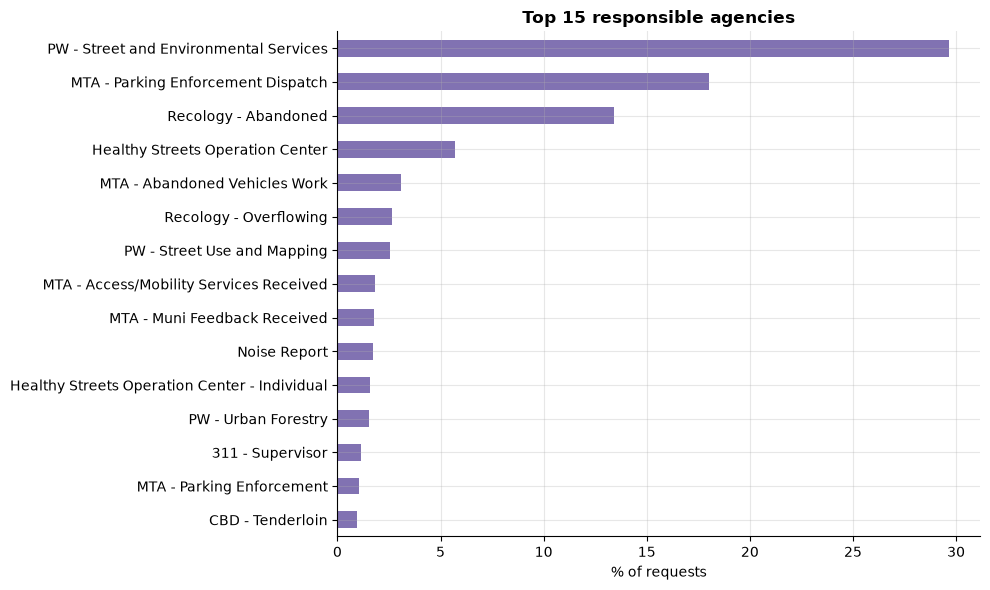

Predicting the most common agency for each subtype is right for 68.8% of cases


In [10]:
agency_counts = df["agency_responsible"].fillna("(missing)").value_counts()
print(f"Distinct agencies: {agency_counts.size}")
print(coverage_stats(agency_counts, "agency_responsible").to_string())

fig, ax = plt.subplots(figsize=(10, 6))
(agency_counts.head(15)[::-1] / len(df) * 100).plot.barh(ax=ax, color="#8172B2")
ax.set_title("Top 15 responsible agencies")
ax.set_xlabel("% of requests")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

# How deterministic is agency given subtype?
g = df.dropna(subset=["service_subtype", "agency_responsible"]).groupby("service_subtype")["agency_responsible"]
top_agency_share = g.agg(lambda s: s.value_counts().iloc[0]).sum() / g.size().sum()
print(f"Predicting the most common agency for each subtype is right for {top_agency_share:.1%} of cases")

Agency names are fine-grained work queues (several per department), with a long tail. A subtype -> most-common-agency lookup is only right for about two thirds of cases (see the printed number), so agency is **not** fully implied by category: the same subtype is split across queues (often by location or workload). Agency routing therefore needs location features or its own model; the lookup is the baseline to beat.

## 6. Source channel mix

,% of requests
source,
Mobile,45.7
Web,35.6
Phone,17.0
(missing),0.9
Integrated Agency,0.7
Twitter,0.0
Email,0.0


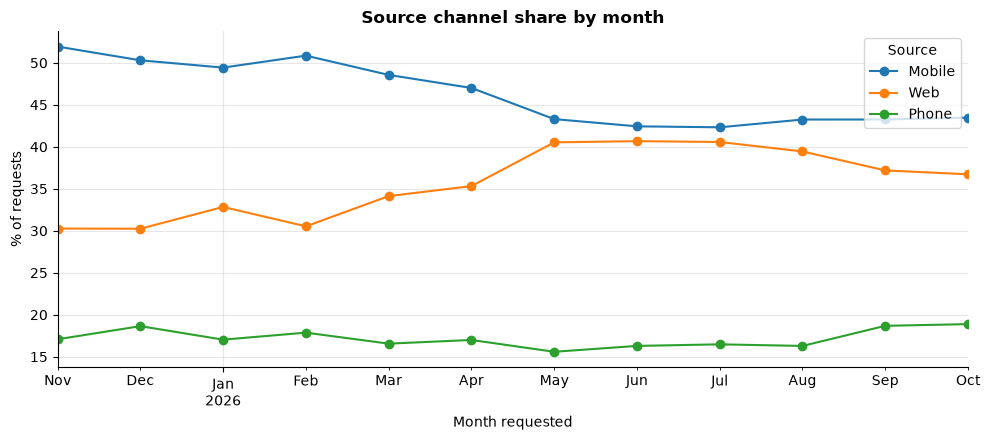

Link type by source (% of row):


link_type,cloudinary,none,other,verint
source,,,,
Email,0.0,100.0,0.0,0.0
Integrated Agency,0.6,99.4,0.0,0.0
Mobile,80.3,19.7,0.0,0.0
Phone,0.2,99.8,0.0,0.0
Twitter,1.6,73.9,24.5,0.0
Web,0.0,10.6,0.0,89.4


In [11]:
src = df["source"].fillna("(missing)").value_counts()
display((src / len(df) * 100).round(1).rename("% of requests").to_frame())

src_month = pd.crosstab(df["month"], df["source"], normalize="index") * 100
main_src = [s for s in src.head(4).index if s in src_month]
fig, ax = plt.subplots()
src_month[main_src].plot(ax=ax, marker="o")
ax.set_title("Source channel share by month")
ax.set_xlabel("Month requested")
ax.set_ylabel("% of requests")
ax.legend(title="Source")
plt.tight_layout()
plt.show()

print("Link type by source (% of row):")
display((pd.crosstab(df["source"], df["link_type"], normalize="index") * 100).round(1))

Mobile and Web dominate. Direct photos come from the Mobile app (Cloudinary, ~80% of mobile cases) and attachments from the Web form (Verint, ~89% of web cases); Phone and agency cases essentially never have media. So "has a photo" is almost entirely a function of channel.

## 7. Photo availability by link type

* **cloudinary** - direct image link from the mobile app (usable for photo models).
* **verint** - web-form attachment page; may or may not be an image (needs checking later).
* **none** - no media.

Only the link host is used; no photo is fetched or shown.

,% of requests
link_type,
cloudinary,36.8
verint,31.8
none,31.4
other,0.0


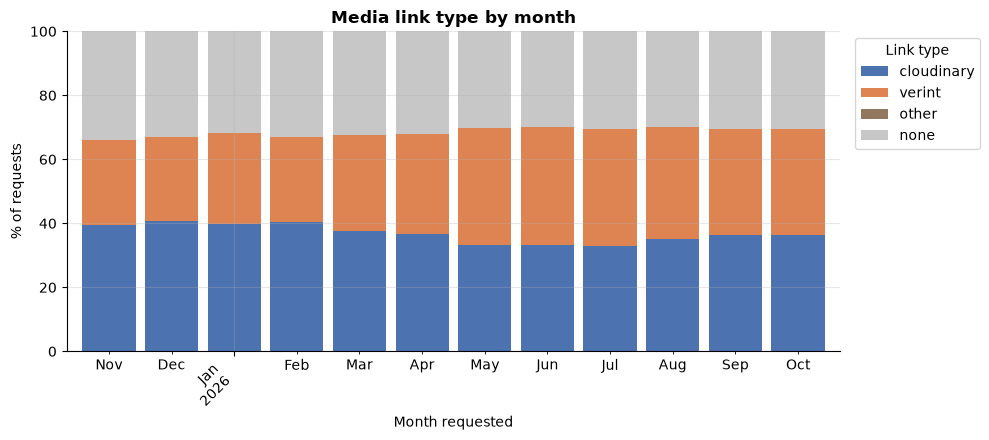

month,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
link_type,,,,,,,,,,,,
cloudinary,39.6,40.8,39.9,40.5,37.7,36.8,33.2,33.2,33.1,35.1,36.3,36.5
verint,26.4,26.1,28.4,26.3,29.8,31.0,36.6,36.8,36.5,35.1,33.1,33.0
other,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
none,33.9,33.1,31.7,33.1,32.5,32.2,30.2,29.9,30.4,29.8,30.5,30.5


In [12]:
lt = df["link_type"].value_counts(normalize=True) * 100
display(lt.round(1).rename("% of requests").to_frame())

colors = {"cloudinary": "#4C72B0", "verint": "#DD8452", "other": "#937860", "none": "#C7C7C7"}
lt_month = pd.crosstab(df["month"], df["link_type"], normalize="index") * 100
cols = [c for c in colors if c in lt_month]
fig, ax = plt.subplots()
lt_month[cols].plot.bar(stacked=True, ax=ax, width=0.85, color=[colors[c] for c in cols])
ax.set_title("Media link type by month")
ax.set_xlabel("Month requested")
ax.set_ylabel("% of requests")
ax.set_ylim(0, 100)
ax.legend(title="Link type", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
lt_month[cols].round(1).T

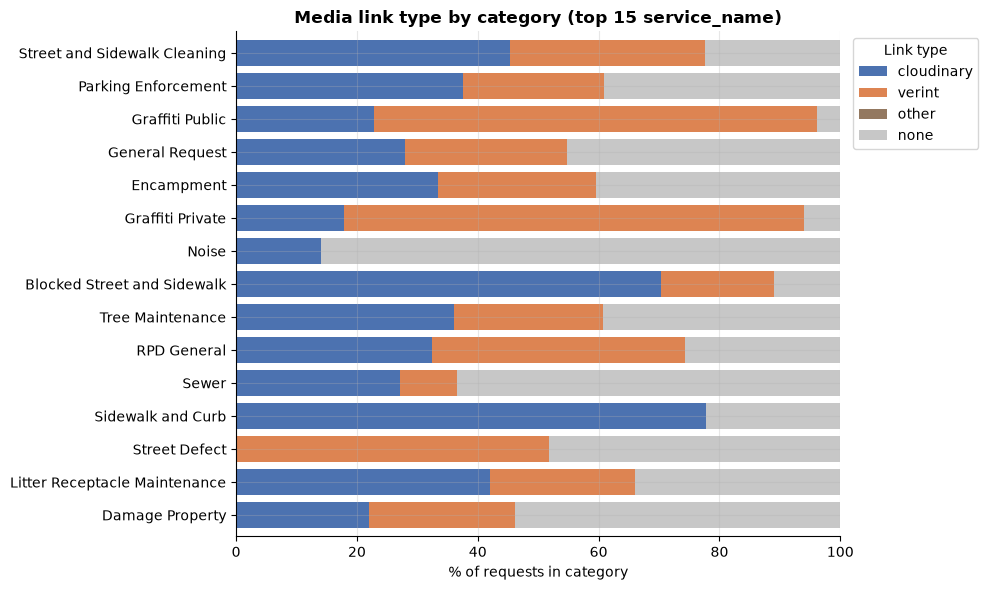

link_type,cloudinary,verint,other,none
service_name,,,,
Street and Sidewalk Cleaning,45.3,32.2,0.0,22.5
Parking Enforcement,37.6,23.3,0.0,39.1
Graffiti Public,22.8,73.4,0.0,3.8
General Request,28.0,26.8,0.0,45.2
Encampment,33.4,26.1,0.1,40.4
Graffiti Private,17.9,76.0,0.0,6.1
Noise,14.0,0.0,0.0,86.0
Blocked Street and Sidewalk,70.3,18.7,0.0,11.0
Tree Maintenance,36.0,24.8,0.0,39.2


In [13]:
top_names = name_counts.head(15).index
sub = df[df["service_name"].isin(top_names)]
lt_cat = pd.crosstab(sub["service_name"], sub["link_type"], normalize="index") * 100
lt_cat = lt_cat.reindex(top_names)[[c for c in colors if c in lt_cat]]
fig, ax = plt.subplots(figsize=(10, 6))
lt_cat[::-1].plot.barh(stacked=True, ax=ax, width=0.8, color=[colors[c] for c in lt_cat.columns])
ax.set_title("Media link type by category (top 15 service_name)")
ax.set_xlabel("% of requests in category")
ax.set_ylabel("")
ax.set_xlim(0, 100)
ax.legend(title="Link type", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()
lt_cat.round(1)

Photo coverage differs a lot between categories. Graffiti and street defects come mostly through the web form (Verint), so whether Verint attachments are real images matters a lot for those classes; noise and sewer cases are mostly photo-less. The Cloudinary share also dropped from about 40% to 33-36% from spring 2026 while Verint rose, so the photo mix shifts over time and a time-based split is needed for the photo model too. Evaluation should report coverage (share of all requests with a usable photo) alongside accuracy.

## 8. Resolution time

`resolution_h = closed_date - requested_datetime` in hours, for cases with a `closed_date`. First check for impossible or suspicious values.

In [14]:
closed = df[df["closed_date"].notna()].copy()
closed["resolution_h"] = (closed["closed_date"] - closed["requested_datetime"]).dt.total_seconds() / 3600
r = closed["resolution_h"]
checks = pd.Series({
    "negative (< 0)": (r < 0).mean() * 100,
    "exactly zero": (r == 0).mean() * 100,
    "0 to 1 minute (incl. zero)": ((r >= 0) & (r < 1 / 60)).mean() * 100,
    "over 90 days": (r > 90 * 24).mean() * 100,
    "over 365 days": (r > 365 * 24).mean() * 100,
}).round(2)
print(f"Cases with closed_date: {len(closed):,}")
display(checks.rename("% of closed cases").to_frame())
print(f"Status 'Closed' but no closed_date: {(df['status_description'].eq('Closed') & df['closed_date'].isna()).sum():,}")
print(f"Status 'Open' but has closed_date: {(df['status_description'].eq('Open') & df['closed_date'].notna()).sum():,}")
display(r.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99]).round(2).to_frame("hours").T)

Cases with closed_date: 821,548


,% of closed cases
negative (< 0),0.17
exactly zero,0.00
0 to 1 minute (incl. zero),0.53
over 90 days,0.79
over 365 days,0.00


Status 'Closed' but no closed_date: 0
Status 'Open' but has closed_date: 0


,count,mean,std,min,10%,25%,50%,75%,90%,95%,99%,max
hours,821548.0,110.87,376.79,-8759.88,0.59,1.8,12.4,51.41,233.29,571.52,1900.63,8886.35


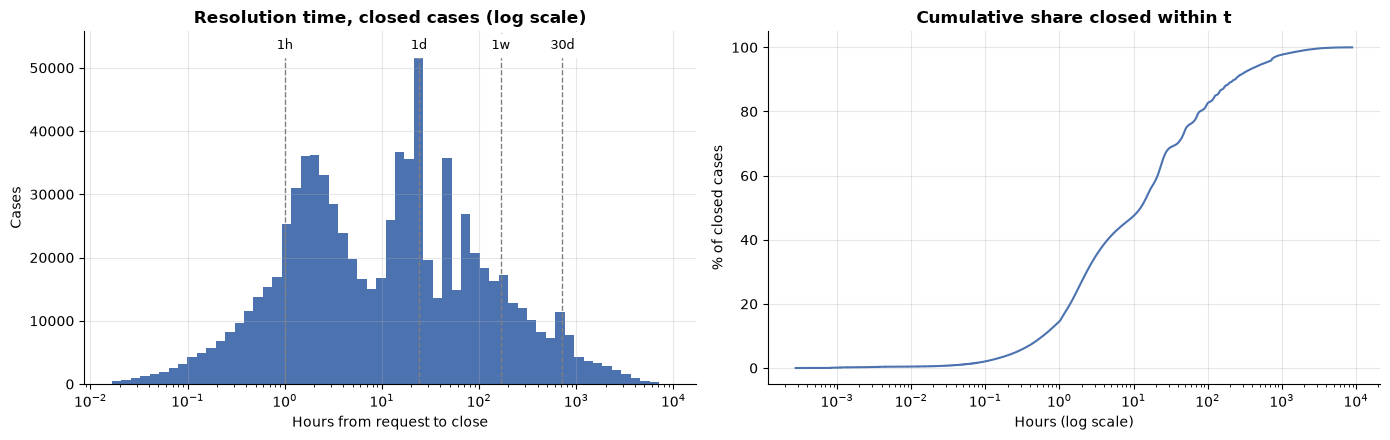

In [15]:
valid = r[r > 0]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
bins = np.logspace(np.log10(1 / 60), np.log10(valid.max() + 1), 60)
axes[0].hist(valid, bins=bins, color="#4C72B0")
axes[0].set_xscale("log")
ymax = axes[0].get_ylim()[1]
for h, lab in [(1, "1h"), (24, "1d"), (24 * 7, "1w"), (24 * 30, "30d")]:
    axes[0].axvline(h, ls="--", c="grey", lw=1)
    axes[0].text(h, ymax * 0.95, lab, ha="center", fontsize=9, backgroundcolor="white")
axes[0].set_title("Resolution time, closed cases (log scale)")
axes[0].set_xlabel("Hours from request to close")
axes[0].set_ylabel("Cases")

sorted_h = np.sort(valid.to_numpy())
axes[1].plot(sorted_h, np.arange(1, len(sorted_h) + 1) / len(sorted_h) * 100, color="#4C72B0")
axes[1].set_xscale("log")
axes[1].set_title("Cumulative share closed within t")
axes[1].set_xlabel("Hours (log scale)")
axes[1].set_ylabel("% of closed cases")
plt.tight_layout()
plt.show()

,cases,median_h,p90_h,p90/median
service_name,,,,
Street and Sidewalk Cleaning,309745,9.2,103.1,11.2
Parking Enforcement,185928,2.7,28.5,10.7
Graffiti Public,61036,134.4,862.3,6.4
General Request,59796,18.4,169.3,9.2
Encampment,35731,18.4,95.5,5.2
Graffiti Private,20603,128.2,1457.2,11.4
Noise,20011,36.3,169.8,4.7
Blocked Street and Sidewalk,17331,1.3,105.8,80.0
RPD General,14147,50.8,491.7,9.7


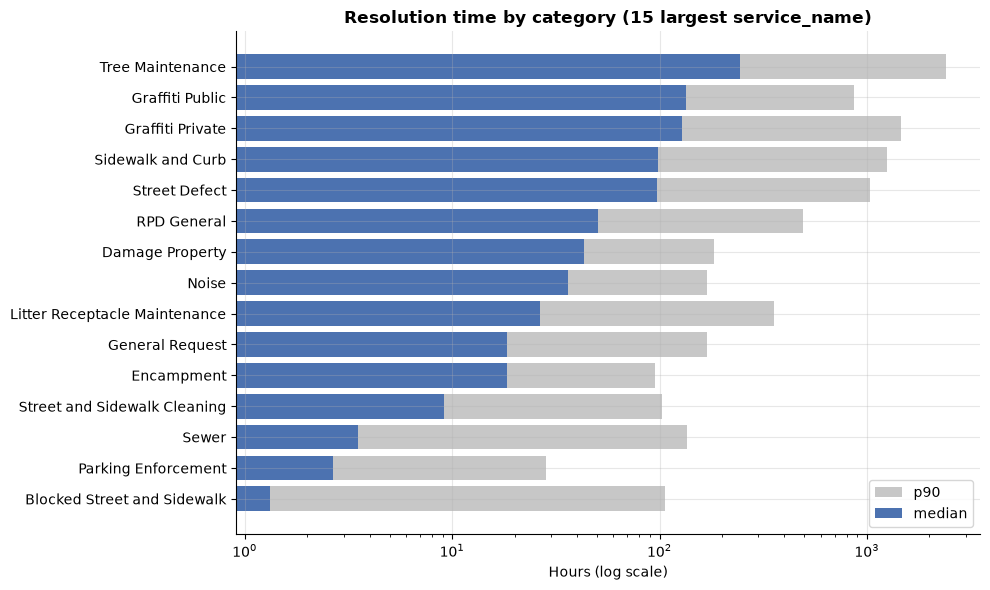

In [16]:
per_cat = (closed[closed["resolution_h"] > 0]
           .groupby("service_name")["resolution_h"]
           .agg(cases="size", median_h="median", p90_h=lambda s: s.quantile(0.9)))
per_cat["p90/median"] = per_cat["p90_h"] / per_cat["median_h"]
per_cat = per_cat[per_cat["cases"] >= 200].sort_values("cases", ascending=False)
display(per_cat.head(20).round(1))

top = per_cat.head(15).sort_values("median_h")
fig, ax = plt.subplots(figsize=(10, 6))
y = np.arange(len(top))
ax.barh(y, top["p90_h"], color="#C7C7C7", label="p90")
ax.barh(y, top["median_h"], color="#4C72B0", label="median")
ax.set_yticks(y, top.index)
ax.set_xscale("log")
ax.set_title("Resolution time by category (15 largest service_name)")
ax.set_xlabel("Hours (log scale)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

Resolution times span several orders of magnitude, both across and within categories (p90 is often many times the median). Implications:
* Model `log1p(hours)` (or a "late" classifier / quantile model), not raw hours.
* "Late" should be defined per category (e.g. beyond that category's historical p90), not with one global threshold.
* Drop negative values (some are off by about a year, likely data-entry errors); treat sub-minute closes as administrative closes and cap extreme durations (p99 is around 1,900 h, the max about a year).
* `status_notes` uses two spellings of the same codes (e.g. `Comment Noted` / `comment_noted`); normalise them. Cases closed as invalid, duplicate, cancelled or "comment noted" are not real resolutions and should be excluded from the resolution-time target regardless of duration.

In [17]:
# What do instant closes look like? Only the short leading code of status_notes is shown.
instant = closed[(closed["resolution_h"] >= 0) & (closed["resolution_h"] < 1 / 60)]
notes = instant["status_notes"].fillna("(none)").str.split(" - ").str[0].str.slice(0, 40)
print(f"{len(instant):,} cases closed in under a minute; most common status_notes codes:")
(notes.value_counts(normalize=True).head(10) * 100).round(1).rename("% of instant closes").to_frame()

4,318 cases closed in under a minute; most common status_notes codes:


,% of instant closes
status_notes,
Comment Noted,40.9
comment_noted,29.4
Case is Invalid,8.1
case_is_invalid,4.9
Case is a Duplicate,4.3
Case Cancelled,3.7
case_cancelled,2.8
case_is_a_duplicate,1.9
Case Resolved,1.1


## 9. Open cases and right-censoring

Open cases have no `closed_date`. Dropping them removes the slowest cases, especially for recent months, so every resolution-time estimate is biased down. Below: share still open by request month, and the age of open cases at download time.

Snapshot time (max updated_datetime): 2026-11-02 23:59:37
Open (no closed_date): 45,184 = 5.2% of all cases


month,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
% still open,2.3,2.6,3.4,3.9,4.3,4.7,4.7,5.2,5.2,5.7,6.8,12.6


,count,mean,std,min,50%,90%,max
open case age (days),45184.0,135.4,102.8,2.0,119.2,288.3,366.8


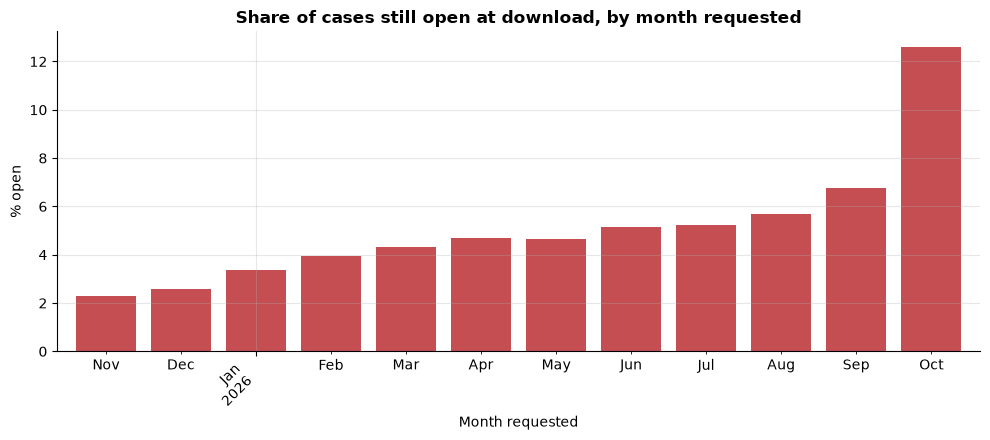

Median resolution of closed cases: latest month 8.7 h vs earlier months 12.8 h


In [18]:
snapshot = df["updated_datetime"].max()
open_ = df[df["closed_date"].isna()].copy()
open_["age_days"] = (snapshot - open_["requested_datetime"]).dt.total_seconds() / 86400
open_share = df["closed_date"].isna().groupby(df["month"]).mean() * 100
print(f"Snapshot time (max updated_datetime): {snapshot}")
print(f"Open (no closed_date): {len(open_):,} = {len(open_) / len(df):.1%} of all cases")
display(open_share.round(1).rename("% still open").to_frame().T)
display(open_["age_days"].describe(percentiles=[0.5, 0.9]).round(1).to_frame("open case age (days)").T)

fig, ax = plt.subplots()
open_share.plot.bar(ax=ax, color="#C44E52", width=0.8)
ax.set_title("Share of cases still open at download, by month requested")
ax.set_xlabel("Month requested")
ax.set_ylabel("% open")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Category medians on the latest month vs older months, closed cases only: shows the censoring bias.
last = df["month"].max()
med_recent = closed.loc[closed["month"] == last].query("resolution_h > 0")["resolution_h"].median()
med_older = closed.loc[closed["month"] < last].query("resolution_h > 0")["resolution_h"].median()
print(f"Median resolution of closed cases: latest month {med_recent:.1f} h vs earlier months {med_older:.1f} h")

**Censoring note.** Recent months look "faster" only because their slow cases are still open. For the resolution-time model:
* use a time-based split and evaluate only on months old enough that nearly all cases have closed, or
* frame the target as "closed within X days" (a binary label that is known once X days have passed), or
* use survival methods that treat open cases as censored at their current age.

The latest month already shows the bias: closed cases from it have a lower median than earlier months only because the slow ones have not closed yet. Many open cases are months old (see the age table), so they are probably stale records and should be checked separately rather than treated as extremely slow cases.

## 10. Location density

Rows with lat/long: 98.8%; inside SF bounding box: 100.0% of those


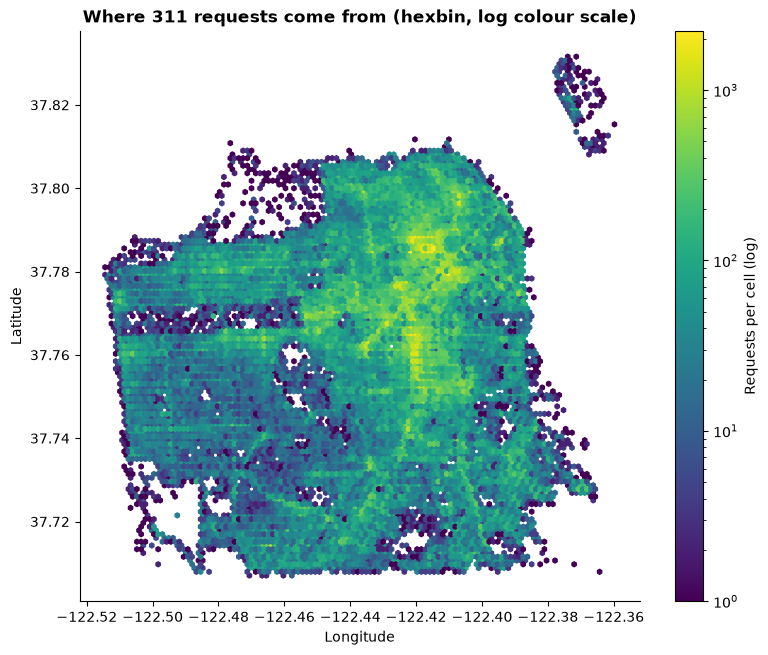

,% of requests
analysis_neighborhood,
Mission,16.4
South of Market,6.5
Tenderloin,5.9
Bayview Hunters Point,4.7
Hayes Valley,4.4
Nob Hill,4.3
Castro/Upper Market,4.1
Sunset/Parkside,3.7
Financial District/South Beach,3.6


In [19]:
geo = df[["lat", "long"]].dropna()
in_sf = geo["lat"].between(37.70, 37.84) & geo["long"].between(-122.52, -122.35)
print(f"Rows with lat/long: {len(geo) / len(df):.1%}; inside SF bounding box: {in_sf.mean():.1%} of those")
geo = geo[in_sf]

fig, ax = plt.subplots(figsize=(8, 7.5))
hb = ax.hexbin(geo["long"], geo["lat"], gridsize=120, bins="log", cmap="viridis", mincnt=1)
ax.set_aspect(1 / np.cos(np.deg2rad(37.77)))
ax.set_title("Where 311 requests come from (hexbin, log colour scale)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.grid(False)
fig.colorbar(hb, ax=ax, label="Requests per cell (log)", shrink=0.8)
plt.tight_layout()
plt.show()

(df["analysis_neighborhood"].value_counts(normalize=True).head(10) * 100).round(1).rename("% of requests").to_frame()

Requests concentrate in the Mission, SoMa, Tenderloin and the north-east; the Mission alone is about one in six requests. Location is clearly informative; neighbourhood or a coarse grid cell is a reasonable feature for both models. Rows outside the SF bounding box should be dropped or have location set to missing.

## 11. Summary of key numbers

In [20]:
summary = pd.Series({
    "files used": ", ".join(p.stem for p in files) if len(files) <= 3
                  else f"{len(files)} months ({files[0].stem[-7:]} to {files[-1].stem[-7:]})",
    "rows (after dropping Test / duplicates)": f"{len(df):,}",
    "has closed_date": f"{df['closed_date'].notna().mean():.1%}",
    "service_name / service_subtype classes": f"{name_counts.size} / {sub_counts.size}",
    "subtypes needed for 90% of volume": int(cov.loc["n for 90%", "service_subtype"]),
    "proposed photo labels (pairs >= 0.5%)": f"{len(keep)} + other, covering {keep.sum():.1%}",
    "coarse photo labels (service_name >= 1%)": f"{len(keep_names)} + other, covering {keep_names.sum():.1%}",
    "cloudinary / verint / none": " / ".join(f"{lt.get(k, 0):.1f}%" for k in ["cloudinary", "verint", "none"]),
    "median / p90 resolution (h)": f"{valid.median():.1f} / {valid.quantile(0.9):.1f}",
    "negative / 0-1 min / >365 d resolution": f"{(r < 0).mean():.2%} / {((r >= 0) & (r < 1 / 60)).mean():.2%} / {(r > 365 * 24).mean():.2%}",
    "agency correct from subtype lookup": f"{top_agency_share:.1%}",
}, name="value")
summary.to_frame()

,value
files used,12 months (2025-11 to 2026-10)
rows (after dropping Test / duplicates),"866,732"
has closed_date,94.8%
service_name / service_subtype classes,42 / 264
subtypes needed for 90% of volume,27
proposed photo labels (pairs >= 0.5%),"20 + other, covering 90.6%"
coarse photo labels (service_name >= 1%),"11 + other, covering 95.1%"
cloudinary / verint / none,36.8% / 31.8% / 31.4%
median / p90 resolution (h),12.5 / 233.8
negative / 0-1 min / >365 d resolution,0.17% / 0.53% / 0.00%
